## Searching the hyperparameters

We now will apply a grid-search to find the best hyperparameters for our model.

In [22]:
%reload_ext autoreload
%autoreload 2
import numpy as np
from implementations import *
from helpers import *
from aux_exploratory_data_analysis import *
from aux_cleaning_functions import *
from aux_preprocessing import *
from aux_grid_search import *
import csv

In [2]:
x_train, x_test, y_train, train_ids, test_ids = load_csv_data("data")
# We transform the data form (-1,1) to (0,1) 
Y_tr = (y_train + 1) / 2

In [3]:
x_train, x_validation, x_te, y_train, y_validation, y_te = split_data(x_train, Y_tr, ratiotrain=0.7, ratiovalidation=0.15, seed=None)

print (x_train.shape, y_train.shape)
print (x_validation.shape, y_validation.shape)
print (x_te.shape, y_te.shape)

(229694, 321) (229694,)
(49220, 321) (49220,)
(49221, 321) (49221,)


We will compute a grid-search over the hyperparameters of the model. We are going to divide the training dataset into a 30% batch of it than mantains the ratio between positive and negative cases due to computational costs. We will compare the modelsby using the f2 score. With this we want to minimize the false negatives, giving more importance to the recall of the model, rather than the accuracy of it as we are working on a medical classification problem. 

In [7]:
best_params, best_f1, results = grid_search_logistic_wheight(
    y_train, x_train,
    y_validation, x_validation,
    thershold_nans = [0.4, 0.3],
    pos_weights=[3, 5, 7, 9],
    methods = ["undersample","weighted"],
    lambdas=[1e-4, 1e-3, 1e-2],
    thresholds=[0.4, 0.5, 0.6, 0.7],
    max_iter= 1000,
    gammas= [0.01, 0.05, 0.1], 
    random_seed = 42
)


=== Run 1/78 (method=undersample,thr_nans = 0.4,gamma = 0.01) ===
Iter     0 | Loss = 0.691276 | Grad = 0.4333
Iter   100 | Loss = 0.584746 | Grad = 0.2426
Iter   200 | Loss = 0.545788 | Grad = 0.1608
Iter   300 | Loss = 0.526691 | Grad = 0.1193
Iter   400 | Loss = 0.515408 | Grad = 0.0950
Iter   500 | Loss = 0.507890 | Grad = 0.0794
Iter   600 | Loss = 0.502461 | Grad = 0.0686
Iter   700 | Loss = 0.498314 | Grad = 0.0606
Iter   800 | Loss = 0.495016 | Grad = 0.0545
Iter   900 | Loss = 0.492312 | Grad = 0.0497
Beta score  F_beta =  0.5066 with threshold =  0.40
New best F_beta = 0.5066 (threshold = 0.40)
Beta score  F_beta =  0.5202 with threshold =  0.50
New best F_beta = 0.5202 (threshold = 0.50)
Beta score  F_beta =  0.5047 with threshold =  0.60
Beta score  F_beta =  0.4355 with threshold =  0.70

=== Run 2/78 (method=weighted,thr_nans = 0.4,gamma = 0.01, lambda = 0.0001, pw = 3) ===
Beta score  F_beta =  0.3366 with threshold =  0.40
Beta score  F_beta =  0.1552 with threshold = 

Now we will compute the full models with the 5 combinations of parameters that maximize the f2 score on the grid_search.

In [9]:
top_5_dicts = [
    {
        "thr_nans": r[0],
        "method": r[1],
        "gamma": r[2],
        "pos_weight": r[3],
        "lambda": r[4],
        "threshold": r[5],
        "fbeta": r[6]
    }
    for r in results[:5]
]

for candidate in top_5_dicts:
    print (f"Training candidate using {candidate['method']} with a value of f_beta score of {candidate['fbeta']}")

Training candidate using undersample with a value of f_beta score of 0.5388819487820112
Training candidate using undersample with a value of f_beta score of 0.5367796345463063
Training candidate using undersample with a value of f_beta score of 0.5357977017221514
Training candidate using undersample with a value of f_beta score of 0.5349909640431233
Training candidate using weighted with a value of f_beta score of 0.528604118993135


We can see that the top four combinations of hyperparameters use the undersample method and the last one use the weighted logistic regression. We will make a comparation between the top combination using undersample method and the top combination using weighted method, as weighted is mathematically stronger than oversample (just random row duplication) we will not consider such option.

NOW WE WILL COMPARE BOTH MODELS 

Iter     0 | Loss = 0.675802 | Grad = 0.4236
Iter   100 | Loss = 0.491788 | Grad = 0.0439
Iter   200 | Loss = 0.480936 | Grad = 0.0254
Iter   300 | Loss = 0.476307 | Grad = 0.0184
Iter   400 | Loss = 0.473630 | Grad = 0.0146
Iter   500 | Loss = 0.471842 | Grad = 0.0123
Iter   600 | Loss = 0.470540 | Grad = 0.0106
Iter   700 | Loss = 0.469541 | Grad = 0.0094
Iter   800 | Loss = 0.468747 | Grad = 0.0084
Iter   900 | Loss = 0.468100 | Grad = 0.0077
Iter  1000 | Loss = 0.467563 | Grad = 0.0070
Iter  1100 | Loss = 0.467110 | Grad = 0.0065
Iter  1200 | Loss = 0.466723 | Grad = 0.0060
Iter  1300 | Loss = 0.466389 | Grad = 0.0056
Iter  1400 | Loss = 0.466097 | Grad = 0.0052
Iter  1500 | Loss = 0.465839 | Grad = 0.0049
Iter  1600 | Loss = 0.465611 | Grad = 0.0047
Iter  1700 | Loss = 0.465406 | Grad = 0.0044
Iter  1800 | Loss = 0.465221 | Grad = 0.0042
Iter  1900 | Loss = 0.465054 | Grad = 0.0040
Iter  2000 | Loss = 0.464901 | Grad = 0.0038
Iter  2100 | Loss = 0.464762 | Grad = 0.0037
Iter  2200

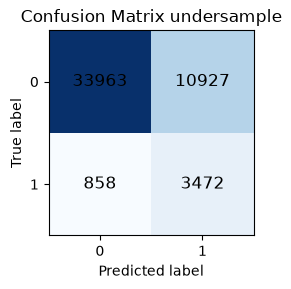

We have obtained a model using undersample with an accuracy of accuracy = 0.7605648110524177, a recall of recall = 0.8018475750577367 and a fbeta score of F_beta = 0.5473060310854693
Confusion Matrix:
[[32833 12057]
 [  874  3456]]
TN=32833, FP=12057, FN=874, TP=3456


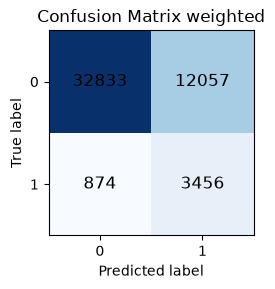

We have obtained a model using weighted with an accuracy of accuracy = 0.7372815928484356, a recall of recall = 0.7981524249422632 and a fbeta score of F_beta = 0.5262997593884201


In [ ]:
final_candidates = [top_5_dicts[0], top_5_dicts[-1]]

modelweights = []
for candidate in final_candidates:
    thr_nans = candidate['thr_nans']
    method = candidate ['method']
    gamma = candidate ['gamma']
    pos_weight = candidate ['pos_weight']
    lambda_ = candidate ['lambda']
    threshold = candidate ['threshold']
    fbeta = candidate ['fbeta']

    X_tr_base = x_train.copy()
    y_tr_base = y_train.copy()
    X_val_base = x_validation.copy()
    y_val_base = y_validation.copy()
    keep_mask = remove_nan_feat(X_tr_base, threshold= thr_nans)

    X_clean_nan_tr = X_tr_base[:,keep_mask]
    X_clean_nan_val = X_val_base[:,keep_mask]
    cat_mask, num_mask = detect_categorical_features(X_clean_nan_tr, max_unique=30)

    X_imp_tr,medians_tr = impute_numerical(X_clean_nan_tr, num_mask, medians=None, means=None, strategy='medians')
    X_imp_tr,modes_tr = impute_categorical(X_imp_tr, cat_mask, modes=None)
    X_imp_val, _ = impute_numerical(X_clean_nan_val, num_mask, medians=medians_tr, strategy='medians')
    X_imp_val, _ = impute_categorical(X_imp_val, cat_mask, modes=modes_tr)
    

    X_std_tr, means_tr, stds_tr= standardize_features(X_imp_tr, num_mask, means=None, stds=None)
    X_std_val, _, _ = standardize_features(X_imp_val, num_mask, means=means_tr, stds=stds_tr)

    X_ohe_tr, categories = one_hot_encode(X_std_tr, cat_mask)   
    X_ohe_val, _ = one_hot_encode(X_std_val, cat_mask,categories = categories)

    mask = feature_target_correlation(X_ohe_tr, y_tr_base, threshold_elimination=0.01)
    X_cleaned_tr = X_ohe_tr[:, mask]
    mask_correlated_variables = filter_colinear_features (X_cleaned_tr, y_tr_base, 0.9)
    X_thr_train = X_cleaned_tr[:, mask_correlated_variables]
    X_thr_val = X_ohe_val[:, mask][:, mask_correlated_variables]

    if (method == 'undersample'):
        X_bal, Y_bal = balance_data (X_thr_train, y_tr_base,method = method, random_state=None)
        w,loss = logistic_regression(Y_bal, X_bal, np.zeros(X_bal.shape[1] + 1), 10000 ,gamma,1e-6)

    else:
        loss, w = logistic_regression_weighted_gd (y_tr_base, X_thr_train, lambda_= lambda_, gamma=gamma, pos_weight=pos_weight, neg_weight=1.0, max_iter=10000, verbose=False)

    modelweights.append(w)
    preds, _ = predict_with_threshold(X_thr_val, w, threshold=threshold)
    fbeta = f_beta_score(y_val_base, preds)
    acc = accuracy_numpy(y_val_base, preds)
    recall = recall_numpy(y_val_base, preds)
    cm = confusion_matrix_numpy(y_val_base, preds, method = method)
    print (f"We have obtained a model using {method} with an accuracy of accuracy = {acc}, a recall of recall = {recall} and a fbeta score of F_beta = {fbeta}")
    


So clearly we can see that the best option is to use the model using the undersample method, as we minimize the number of false negatives while mantaining a high number of corrected predicted outputs, we can notice such fact in the recall value. We can now set those parameters as the best paramters and just compute a final test computation on the best model.

Confusion Matrix:
[[33885 10942]
 [  884  3510]]
TN=33885, FP=10942, FN=884, TP=3510


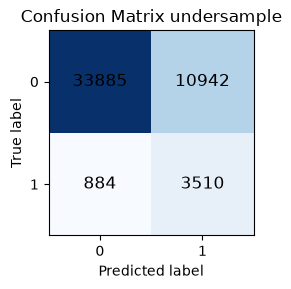

We have obtained a model using undersample with an accuracy of accuracy = 0.75973669775096, a recall of recall = 0.7988165680473372 and a fbeta score of F_beta = 0.5479580367178719


In [ ]:
winning_candidate = final_candidates[0]
best_weights = modelweights[0]

thr_nans = winning_candidate["thr_nans"]
opt_threshold = winning_candidate["threshold"]


X_tr_base = x_train.copy()
y_tr_base = y_train.copy()
X_te_base = x_te.copy()
y_te_base = y_te.copy()
keep_mask = remove_nan_feat(X_tr_base, threshold= thr_nans)

X_clean_nan_tr = X_tr_base[:,keep_mask]
X_clean_nan_te = X_te_base[:,keep_mask]
X_clean_nan_test = x_test[:,keep_mask]
cat_mask, num_mask = detect_categorical_features(X_clean_nan_tr, max_unique=30)

X_imp_tr,medians_tr = impute_numerical(X_clean_nan_tr, num_mask, medians=None, means=None, strategy='medians')
X_imp_tr,modes_tr = impute_categorical(X_imp_tr, cat_mask, modes=None)
X_imp_te, _ = impute_numerical(X_clean_nan_te, num_mask, medians=medians_tr, strategy='medians')
X_imp_te, _ = impute_categorical(X_imp_te, cat_mask, modes=modes_tr)
X_imp_test, _ = impute_numerical(X_clean_nan_test, num_mask, medians=medians_tr, strategy='medians')
X_imp_test, _ = impute_categorical(X_imp_test, cat_mask, modes=modes_tr)

X_std_tr, means_tr, stds_tr= standardize_features(X_imp_tr, num_mask, means=None, stds=None)
X_std_te, _, _ = standardize_features(X_imp_te, num_mask, means=means_tr, stds=stds_tr)
X_std_test, _, _ = standardize_features(X_imp_test, num_mask, means=means_tr, stds=stds_tr)


X_ohe_tr, categories = one_hot_encode(X_std_tr, cat_mask)   
X_ohe_te, _ = one_hot_encode(X_std_te, cat_mask,categories = categories)
X_ohe_test, _ = one_hot_encode(X_std_test, cat_mask,categories = categories)


mask = feature_target_correlation(X_ohe_tr, y_tr_base, threshold_elimination=0.01)
X_cleaned_tr = X_ohe_tr[:, mask]
mask_correlated_variables = filter_colinear_features (X_cleaned_tr, y_tr_base, 0.9)
X_thr_train = X_cleaned_tr[:, mask_correlated_variables]
X_thr_te = X_ohe_te[:, mask][:, mask_correlated_variables]
X_thr_test = X_ohe_test[:, mask][:, mask_correlated_variables]

preds, _ = predict_with_threshold(X_thr_te, best_weights, threshold = opt_threshold)
fbeta = f_beta_score(y_te_base, preds)
acc = accuracy_numpy(y_te_base, preds)
recall = recall_numpy(y_te_base, preds)
cm = confusion_matrix_numpy(y_te_base, preds, method = winning_candidate["method"])
print (f"We have obtained a model using {winning_candidate["method"]} with an accuracy of accuracy = {acc}, a recall of recall = {recall} and a fbeta score of F_beta = {fbeta}")


In [ ]:

y_pred_final = 